### 1. Setup Inicial e Montagem do Google Drive

In [ ]:
# Importar bibliotecas essenciais
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from numpy.fft import fft, fftshift, fftfreq

# Machine Learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from imblearn.combine import SMOTEENN  # Balanceamento (se necessário)

# Configuração de visualização
plt.rcParams.update({'figure.figsize': (12, 5), 'font.size': 10})
sns.set_palette("husl")

print("Bibliotecas importadas com sucesso")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Caminhos dos arquivos TEXBAT
# COLAB: use '/content/drive/MyDrive/SinaisSistemas/'
# LOCAL: use '../' ou caminho absoluto

BASE_PATH = '/content/drive/MyDrive/SinaisSistemas/'  # Ajuste conforme necessário
clean_filename = os.path.join(BASE_PATH, 'clean_static.bin')
spoof_filename = os.path.join(BASE_PATH, 'ds2.bin')

# Verificar existência
for f in [clean_filename, spoof_filename]:
    if not os.path.exists(f):
        raise FileNotFoundError(f"Arquivo não encontrado: {f}")
    print(f"Arquivo encontrado: {f}")

print("\nArquivos TEXBAT carregados com sucesso!")

### 2. Configuração dos Parâmetros do Sinal GPS

**Conceito (Sinais e Sistemas):**  
GPS L1 C/A opera em 1575.42 MHz com código PRN de taxa 1.023 Mcps (Mega chips por segundo). O sinal é amostrado a 25 MHz (taxa de Nyquist bem acima da banda útil de ~2 MHz) para capturar toda a informação espectral sem aliasing.

In [ ]:
# Parâmetros do sinal GPS L1 C/A
fs = 25_000_000  # Taxa de amostragem: 25 MHz (Sampling Frequency)
bytes_per_sample = 4  # 2 bytes I (In-phase) + 2 bytes Q (Quadrature) = amostra complexa

# Parâmetros de janelamento
window_size = 32768  # 2^15 amostras ≈ 1.31 ms @ 25 MHz
                     # Janela temporal suficiente para análise espectral com boa resolução

# Informações dos arquivos
clean_samples = os.path.getsize(clean_filename) // bytes_per_sample
spoof_samples = os.path.getsize(spoof_filename) // bytes_per_sample

print("="*70)
print("INFORMAÇÕES DOS ARQUIVOS TEXBAT")
print("="*70)
print(f"\n cleanStatic.bin (Cenário Autêntico)")
print(f"   Amostras: {clean_samples:,}")
print(f"   Duração:  {clean_samples/fs:.2f} segundos")
print(f"   Label:    0 (Autêntico) - todo o arquivo")

print(f"\n ds2.bin (Cenário com Ataque Overpowering)")
print(f"   Amostras: {spoof_samples:,}")
print(f"   Duração:  {spoof_samples/fs:.2f} segundos")
print(f"   ATENÇÃO: Ataque começa em ~110-120s!")
print(f"   Labeling: t < 110s → Label 0 (Autêntico)")
print(f"             t ≥ 110s → Label 1 (Spoofing)")
print("="*70)

### 3. Funções de Leitura e Processamento de Sinais

**Conceito (Sinais e Sistemas):**  
Trabalhamos com sinais complexos I+jQ (representação em banda base). A janela de Hann reduz o "vazamento espectral" (leakage) ao aplicar a FFT, suavizando as bordas do segmento temporal analisado - isso é essencial para análise espectral precisa.

In [ ]:
def read_window_at_time(mm, t_sec, win_N, N_samples, fs=25_000_000):
    """
    Lê uma janela de amostras IQ centrada no tempo t_sec

    Args:
        mm: memmap do arquivo binário
        t_sec: tempo central da janela (segundos)
        win_N: tamanho da janela em amostras
        N_samples: total de amostras no arquivo
        fs: taxa de amostragem

    Returns:
        ndarray complexo (I + jQ) com win_N amostras

    Teoria (Sinais e Sistemas):
        - Sinal GPS é amostrado em I/Q (representação complexa em banda base)
        - I = componente em fase, Q = componente em quadratura
        - Sinal complexo x(t) = I(t) + j*Q(t) preserva amplitude e fase
    """
    ctr = int(t_sec * fs)  # Índice central
    half = win_N // 2

    # Garantir limites válidos
    start = max(0, ctr - half)
    end = min(N_samples, start + win_N)
    start = max(0, end - win_N)

    # Ler segmento do arquivo (memmap eficiente, sem carregar tudo na RAM)
    i0, i1 = 2 * start, 2 * end
    seg = mm[i0:i1]

    # Separar I (pares) e Q (ímpares)
    I = seg[0::2].astype(np.float32)
    Q = seg[1::2].astype(np.float32)

    return I + 1j * Q  # Sinal complexo

### 4. Extração de Características (Features) do Sinal

**Conceito (Sinais e Sistemas):**  
Estas features capturam propriedades fundamentais do sinal no domínio tempo-frequência:

1. **Potência in-band** (Energia): ∫|X(f)|² df em ±1 MHz - mede energia espectral concentrada
2. **C/N₀** (Carrier-to-Noise): Razão sinal/ruído - métrica SQM crítica em GPS
3. **Centróide espectral**: Frequência média ponderada - detecta shifts Doppler anômalos
4. **Spread espectral**: Dispersão em frequência - mede "largura" do sinal
5. **Kurtosis**: Medida de "spikiness" - detecta picos anormais (overpower)
6. **Peak power**: Máximo da FFT - overpower aumenta drasticamente este valor

**Conexão com Correlação:**  
O pico de correlação GPS está relacionado à potência in-band e C/N₀. Um ataque de overpower aumenta artificialmente esses valores, distorcendo o pico de correlação normal.

In [ ]:
def extract_features(x, fs=25_000_000):
    """
    Extrai 6 features espectrais/temporais de uma janela de sinal GPS

    Estas features são baseadas em:
    - Análise de Fourier (domínio da frequência)
    - Análise estatística (momentos do espectro)
    - Signal Quality Monitoring (SQM) - métricas de integridade

    Args:
        x: sinal complexo I+jQ (ndarray)
        fs: taxa de amostragem

    Returns:
        dict com 6 features extraídas
    """
    features = {}
    N = len(x)

    # ===================================================================
    # JANELAMENTO E FFT
    # ===================================================================
    # Teoria: Janela de Hann reduz vazamento espectral (leakage)
    # w(n) suaviza bordas → menos artefatos na FFT
    w = np.hanning(N).astype(np.float32)

    # FFT com janelamento: X(f) = FFT[x(t) * w(t)]
    # fftshift coloca DC (f=0) no centro do vetor
    X = fftshift(fft(x * w))
    freqs = fftshift(fftfreq(N, d=1/fs))

    # Máscara para banda GPS útil (±1 MHz ao redor de DC)
    mask_1mhz = np.abs(freqs) <= 1_000_000.0

    # ===================================================================
    # FEATURE 1: POTÊNCIA IN-BAND (dB)
    # ===================================================================
    # Teoria: Potência = ∫|X(f)|² df normalizada pela energia da janela
    # Parseval: energia no tempo = energia na frequência
    # Overpower aumenta drasticamente esta métrica
    power_linear = float(np.sum(np.abs(X[mask_1mhz])**2) / np.sum(w**2))
    features['power_db'] = 10.0 * np.log10(power_linear + 1e-20)

    # ===================================================================
    # FEATURES 2 e 3: CENTRÓIDE E SPREAD ESPECTRAL
    # ===================================================================
    # Teoria: Centróide = "centro de massa" do espectro
    #         fc = Σ(f * |X(f)|²) / Σ|X(f)|²
    # Detecta deslocamentos Doppler anômalos causados por spoofing
    P = (np.abs(X)**2)[mask_1mhz]
    F = freqs[mask_1mhz]
    denom = float(np.sum(P)) + 1e-30

    features['centroid_hz'] = float(np.sum(F * P) / denom)

    # Spread (desvio padrão espectral) = largura da distribuição
    # Σ((f - fc)² * |X(f)|²) / Σ|X(f)|²
    mean_freq = features['centroid_hz']
    features['spectral_spread'] = float(np.sqrt(np.sum(((F - mean_freq)**2) * P) / denom))

    # ===================================================================
    # FEATURE 4: PICO DE POTÊNCIA
    # ===================================================================
    # Máximo absoluto da FFT - overpower cria pico anormal
    features['peak_power'] = float(np.max(np.abs(X)))

    # ===================================================================
    # FEATURE 5: KURTOSIS (4º momento)
    # ===================================================================
    # Teoria: Kurtosis mede "spikiness" da distribuição
    # k = E[(X - μ)⁴] / σ⁴
    # Valores altos indicam picos anormais (outliers espectrais)
    X_abs = np.abs(X)
    mean_X, std_X = np.mean(X_abs), np.std(X_abs)
    features['kurtosis'] = float(np.mean((X_abs - mean_X)**4) / (std_X**4 + 1e-10))

    # ===================================================================
    # FEATURE 6: C/N₀ APROXIMADO (SQM CRÍTICA)
    # ===================================================================
    # Teoria: C/N₀ = razão portadora/densidade de ruído [dB-Hz]
    # Métrica fundamental de qualidade GPS (Signal Quality Monitoring)
    # C = potência do sinal em ±1.023 MHz
    # N₀ = densidade espectral de ruído (estimado em bandas afastadas)

    S = (np.abs(X)**2) / (fs * np.sum(w**2))  # PSD (Power Spectral Density)
    df = freqs[1] - freqs[0]

    # Estimar centro espectral em banda mais larga (±2 MHz)
    band2 = np.abs(freqs) <= 2.0e6
    fc = float(np.sum(freqs[band2] * S[band2]) / (np.sum(S[band2]) + 1e-30))

    # Máscaras: sinal em ±1.023 MHz, ruído em bandas laterais (1.5-3.5 MHz)
    sig_mask = np.abs(freqs - fc) <= 1.023e6
    noise_mask = (np.abs(freqs - fc) >= 1.5e6) & (np.abs(freqs - fc) <= 3.5e6)

    if np.any(noise_mask):
        N0 = float(np.median(S[noise_mask]))  # Densidade de ruído
        P_band = float(np.sum(S[sig_mask]) * df)  # Potência do sinal
        C_est = max(P_band - N0 * 2 * 1.023e6, 1e-30)  # Subtrai contribuição do ruído
        features['cn0_dbhz'] = 10.0 * np.log10(C_est / (N0 + 1e-30))
    else:
        features['cn0_dbhz'] = np.nan

    return features

print("Função de extração de features definida")
print("\nFeatures Extraídas (baseadas em Correlação e Análise Espectral):")
print("   1. power_db:         Potência in-band (±1 MHz) [dB]")
print("   2. centroid_hz:      Centróide espectral (Doppler proxy) [Hz]")
print("   3. spectral_spread:  Largura espectral (dispersão) [Hz]")
print("   4. peak_power:       Pico de potência da FFT")
print("   5. kurtosis:         Curtose (4º momento - spikiness)")
print("   6. cn0_dbhz:         C/N₀ aproximado (SQM) [dB-Hz]")

### 5. Criação do Dataset com Labeling Inteligente (Anti-Viés)

** CRÍTICO (Especificação do Projeto):**  
O arquivo `ds2.bin` contém sinal **autêntico até ~110s**, depois o ataque de overpower começa. Rotular tudo como spoofing seria um **erro grave** que "sujaria" o treinamento.

**Estratégia de Labeling:**
- `cleanStatic.bin`: **Todo o arquivo → Label 0** (autêntico)
- `ds2.bin`:
  - **t < 110s → Label 0** (ainda autêntico, pré-ataque)
  - **t ≥ 110s → Label 1** (spoofing ativo, overpower)

**Amostragem Não-Sobreposta:** Garante independência estatística entre janelas (evita vazamento de dados).

In [ ]:
def sample_nonoverlapping_centers(N_samples, window_size, n_windows, t_min=None, t_max=None, fs=25_000_000, seed=42):
    """
    Amostra centros de janelas não-sobrepostas (anti-vazamento de dados)
    🔧 OTIMIZADO: Usa grid spacing em vez de filtrar array repetidamente

    Teoria (Validação Estatística):
        - Janelas sobrepostas criam dependência entre amostras
        - Para garantir independência, espaçamos centros por > window_size
        - Isso evita que o modelo "memorize" janelas adjacentes
    """
    np.random.seed(seed)
    half = window_size // 2

    # Converter tempos para índices
    idx_min = half if t_min is None else max(half, int(t_min * fs))
    idx_max = (N_samples - half) if t_max is None else min(N_samples - half, int(t_max * fs))

    if idx_max <= idx_min:
        return np.array([], dtype=int)

    # ===================================================================
    # OTIMIZAÇÃO: Criar grid de posições válidas (espaçadas por window_size)
    # Em vez de filtrar array a cada iteração, criamos posições discretas
    # ===================================================================
    step = window_size + 1  # Garantir espaçamento > window_size
    n_possible = (idx_max - idx_min) // step

    if n_possible < n_windows:
        # Se não há espaço suficiente para n_windows, reduzir step
        step = max(half, (idx_max - idx_min) // n_windows)
        n_possible = (idx_max - idx_min) // step

    # Criar grid de centros possíveis
    possible_centers = np.arange(idx_min, idx_max, step, dtype=int)

    # Amostrar aleatoriamente n_windows centros do grid
    n_to_sample = min(n_windows, len(possible_centers))
    chosen_indices = np.random.choice(len(possible_centers), size=n_to_sample, replace=False)
    chosen = possible_centers[chosen_indices]

    return chosen


def create_labeled_dataset(clean_file, spoof_file,
                           n_clean=2000, n_spoof_pre=500, n_spoof_post=1500,
                           window_size=32768, attack_start_time=110, seed=42):
    """
    Cria dataset com labeling inteligente e amostragem não-sobreposta

    Especificação do Projeto:
        - Foco em integridade do sinal e detecção baseada em correlação
        - Features extraídas capturam distorções no pico de correlação
        - Labeling cuidadoso evita viés nos dados de treino
    """
    # Abrir arquivos em memmap (eficiente para arquivos grandes)
    clean_mm = np.memmap(clean_file, dtype=np.int16, mode='r')
    spoof_mm = np.memmap(spoof_file, dtype=np.int16, mode='r')

    N_clean = len(clean_mm) // 4
    N_spoof = len(spoof_mm) // 4

    features_list = []
    labels = []
    times = []  # Guardar timestamp para análise posterior
    sources = []  # Guardar origem (clean/spoof_pre/spoof_post)

    print("="*70)
    print("CRIANDO DATASET COM LABELING INTELIGENTE")
    print("="*70)

    # ===================================================================
    # PARTE 1: SINAL LIMPO (cleanStatic.bin) → Label 0
    # ===================================================================
    print(f"\nProcessando cleanStatic.bin ({n_clean} janelas)...")
    print(f"   Label: 0 (Autêntico) - todo o arquivo")

    centers = sample_nonoverlapping_centers(N_clean, window_size, n_clean, seed=seed)

    for i, center in enumerate(centers):
        t_sec = center / fs
        window = read_window_at_time(clean_mm, t_sec, window_size, N_clean, fs)

        if len(window) == window_size:
            features_list.append(extract_features(window, fs))
            labels.append(0)  # Autêntico
            times.append(t_sec)
            sources.append('clean')

        if (i + 1) % 500 == 0:
            print(f"   Progresso: {i+1}/{len(centers)}")

    n_clean_extracted = sum(1 for s in sources if s == 'clean')
    print(f"{n_clean_extracted} janelas extraídas (Label 0)")

    # ===================================================================
    # PARTE 2: ds2.bin PRÉ-ATAQUE (t < 110s) → Label 0
    # ===================================================================
    print(f"\nProcessando ds2.bin PRÉ-ATAQUE (t < {attack_start_time}s, {n_spoof_pre} janelas)...")
    print(f"Label: 0 (Ainda autêntico - ataque não começou)")
    print(f"CRÍTICO: Evitar rotular pré-ataque como spoofing!")

    centers = sample_nonoverlapping_centers(
        N_spoof, window_size, n_spoof_pre,
        t_min=10, t_max=attack_start_time,
        fs=fs, seed=seed+1
    )

    for i, center in enumerate(centers):
        t_sec = center / fs
        window = read_window_at_time(spoof_mm, t_sec, window_size, N_spoof, fs)

        if len(window) == window_size:
            features_list.append(extract_features(window, fs))
            labels.append(0)  # Ainda autêntico!
            times.append(t_sec)
            sources.append('spoof_pre')

        if (i + 1) % 250 == 0:
            print(f"   Progresso: {i+1}/{len(centers)}")

    n_pre_extracted = sum(1 for s in sources if s == 'spoof_pre')
    print(f"{n_pre_extracted} janelas extraídas (Label 0)")

    # ===================================================================
    # PARTE 3: ds2.bin PÓS-ATAQUE (t ≥ 110s) → Label 1
    # ===================================================================
    print(f"\nProcessando ds2.bin PÓS-ATAQUE (t ≥ {attack_start_time}s, {n_spoof_post} janelas)...")
    print(f"   Label: 1 (Spoofing ativo - Overpower)")

    centers = sample_nonoverlapping_centers(
        N_spoof, window_size, n_spoof_post,
        t_min=attack_start_time + 10,  # Buffer de segurança (10s após início)
        fs=fs, seed=seed+2
    )

    for i, center in enumerate(centers):
        t_sec = center / fs
        window = read_window_at_time(spoof_mm, t_sec, window_size, N_spoof, fs)

        if len(window) == window_size:
            features_list.append(extract_features(window, fs))
            labels.append(1)  # Spoofing!
            times.append(t_sec)
            sources.append('spoof_post')

        if (i + 1) % 500 == 0:
            print(f"Progresso: {i+1}/{len(centers)}")

    n_post_extracted = sum(1 for s in sources if s == 'spoof_post')
    print(f"{n_post_extracted} janelas extraídas (Label 1)")

    # ===================================================================
    # CRIAR DATAFRAME
    # ===================================================================
    df = pd.DataFrame(features_list).dropna()
    df['label'] = pd.Series(labels).loc[df.index]
    df['time'] = pd.Series(times).loc[df.index]
    df['source'] = pd.Series(sources).loc[df.index]

    print("\n" + "="*70)
    print("DATASET FINAL")
    print("="*70)
    print(f"Total de amostras: {len(df)}")
    print(f"\nDistribuição por Label:")
    print(df['label'].value_counts().sort_index())
    print(f"\nDistribuição por Origem:")
    print(df['source'].value_counts())
    print("="*70)

    return df

# EXECUTAR CRIAÇÃO DO DATASET
print("Iniciando extração de features e labeling...\n")
df_full = create_labeled_dataset(
    clean_filename, spoof_filename,
    n_clean=2500, n_spoof_pre=500, n_spoof_post=1500,
    attack_start_time=110
)

print("\nDataset criado com sucesso!")
print(f"\nPrimeiras linhas:")
print(df_full.head(10))

Iniciando extração de features e labeling...

CRIANDO DATASET COM LABELING INTELIGENTE

Processando cleanStatic.bin (2500 janelas)...
   Label: 0 (Autêntico) - todo o arquivo
   Progresso: 500/2500
   Progresso: 1000/2500
   Progresso: 1500/2500
   Progresso: 2000/2500
   Progresso: 2500/2500
2500 janelas extraídas (Label 0)

Processando ds2.bin PRÉ-ATAQUE (t < 110s, 500 janelas)...
Label: 0 (Ainda autêntico - ataque não começou)
CRÍTICO: Evitar rotular pré-ataque como spoofing!
   Progresso: 250/500
   Progresso: 500/500
500 janelas extraídas (Label 0)

Processando ds2.bin PÓS-ATAQUE (t ≥ 110s, 1500 janelas)...
   Label: 1 (Spoofing ativo - Overpower)
Progresso: 500/1500
Progresso: 1000/1500
Progresso: 1500/1500
1500 janelas extraídas (Label 1)

DATASET FINAL
Total de amostras: 4500

Distribuição por Label:
label
0    3000
1    1500
Name: count, dtype: int64

Distribuição por Origem:
source
clean         2500
spoof_post    1500
spoof_pre      500
Name: count, dtype: int64

Dataset cri

### 6. Separação Treino/Teste com Shuffle (Anti-Memorização Temporal)

**Conceito (Machine Learning + Sinais):**  
Por que `shuffle=True` é **essencial**:

1. **Sem shuffle**: O modelo vê primeiro todas as janelas de um período, depois de outro. Ele pode aprender padrões temporais específicos (ex: "depois da amostra 2000 sempre vem spoofing") em vez de aprender a **forma** do sinal.

2. **Com shuffle**: Embaralhar força o modelo a aprender apenas as **características espectrais** (potência, C/N₀, centróide) que diferenciam spoofing de autêntico, independente da ordem temporal. Isso é o que queremos - generalização baseada na **física do sinal**, não na sequência temporal.

**Analogia:** É como ensinar a reconhecer frutas. Sem shuffle seria mostrar 100 maçãs seguidas, depois 100 laranjas - o modelo poderia aprender "a fruta 101 é sempre diferente da 100". Com shuffle, ele aprende cores, formas e texturas (features intrínsecas).

In [ ]:
# Separar features e labels
feature_cols = ['power_db', 'centroid_hz', 'spectral_spread', 'peak_power', 'kurtosis', 'cn0_dbhz']
X = df_full[feature_cols]
y = df_full['label']

# Train/Test Split com SHUFFLE
# Especificação do Projeto: Validação realista anti-memorização
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 80% treino, 20% teste
    shuffle=True,        # CRÍTICO: embaralhar para aprender features, não ordem temporal
    random_state=42,     # Reprodutibilidade
    stratify=y           # Manter proporção de classes
)

print("="*70)
print("SEPARAÇÃO TREINO/TESTE")
print("="*70)
print(f"\nTotal de amostras: {len(X)}")
print(f"\nConjunto de TREINO:")
print(f"   Amostras: {len(X_train)}")
print(f"   Label 0 (Autêntico): {sum(y_train == 0)}")
print(f"   Label 1 (Spoofing):  {sum(y_train == 1)}")

print(f"\nConjunto de TESTE:")
print(f"   Amostras: {len(X_test)}")
print(f"   Label 0 (Autêntico): {sum(y_test == 0)}")
print(f"   Label 1 (Spoofing):  {sum(y_test == 1)}")

print(f"\nPOR QUE SHUFFLE=TRUE?")
print(f"   - Embaralhar FORÇA o modelo a aprender a FORMA do sinal (features)")
print(f"   - SEM shuffle: modelo pode memorizar padrões temporais específicos")
print(f"   - COM shuffle: modelo aprende características espectrais invariantes")
print(f"   - Analogia: Aprender a reconhecer frutas por cor/forma, não por ordem")
print("="*70)

SEPARAÇÃO TREINO/TESTE

Total de amostras: 4500

Conjunto de TREINO:
   Amostras: 3600
   Label 0 (Autêntico): 2400
   Label 1 (Spoofing):  1200

Conjunto de TESTE:
   Amostras: 900
   Label 0 (Autêntico): 600
   Label 1 (Spoofing):  300

POR QUE SHUFFLE=TRUE?
   - Embaralhar FORÇA o modelo a aprender a FORMA do sinal (features)
   - SEM shuffle: modelo pode memorizar padrões temporais específicos
   - COM shuffle: modelo aprende características espectrais invariantes
   - Analogia: Aprender a reconhecer frutas por cor/forma, não por ordem


### 7. Pré-processamento: Normalização com StandardScaler

**Conceito (Machine Learning):**  
Normalização (z-score) garante que features com escalas diferentes (ex: potência em dB vs kurtosis adimensional) tenham peso comparável no Random Forest. Sem normalização, features com valores maiores dominariam o aprendizado.

**Fórmula:** z = (x - μ) / σ  
(Cada feature fica com média 0 e desvio padrão 1)

In [ ]:
# Normalização (StandardScaler)
# Importante: fit apenas no treino, transform em treino E teste
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Converter de volta para DataFrame (para manter nomes das colunas)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_cols, index=X_test.index)

print("Normalização (StandardScaler) aplicada")
print(f"\nExemplo de transformação (primeira amostra de treino):")
print(f"Antes:  {X_train.iloc[0].values}")
print(f"Depois: {X_train_scaled.iloc[0].values}")

Normalização (StandardScaler) aplicada

Exemplo de transformação (primeira amostra de treino):
Antes:  [ 1.04826546e+02 -1.00678399e+04  4.77630067e+05  1.15697562e+06
  4.24223328e+00  6.57942371e+01]
Depois: [ 0.41173666  0.50755686  0.80730019 -0.65921094 -0.70202927 -0.6869138 ]


## 8. Análise de Correlação entre Features (Spearman)

**Conceito (Estatística + Sinais):**  
Matriz de correlação de Spearman mede dependências não-lineares entre features. Features altamente correlacionadas são redundantes - remover uma delas pode simplificar o modelo sem perder informação.

**Interpretação:**
- Correlação próxima de ±1: Features redundantes
- Correlação próxima de 0: Features independentes (mais informativas)

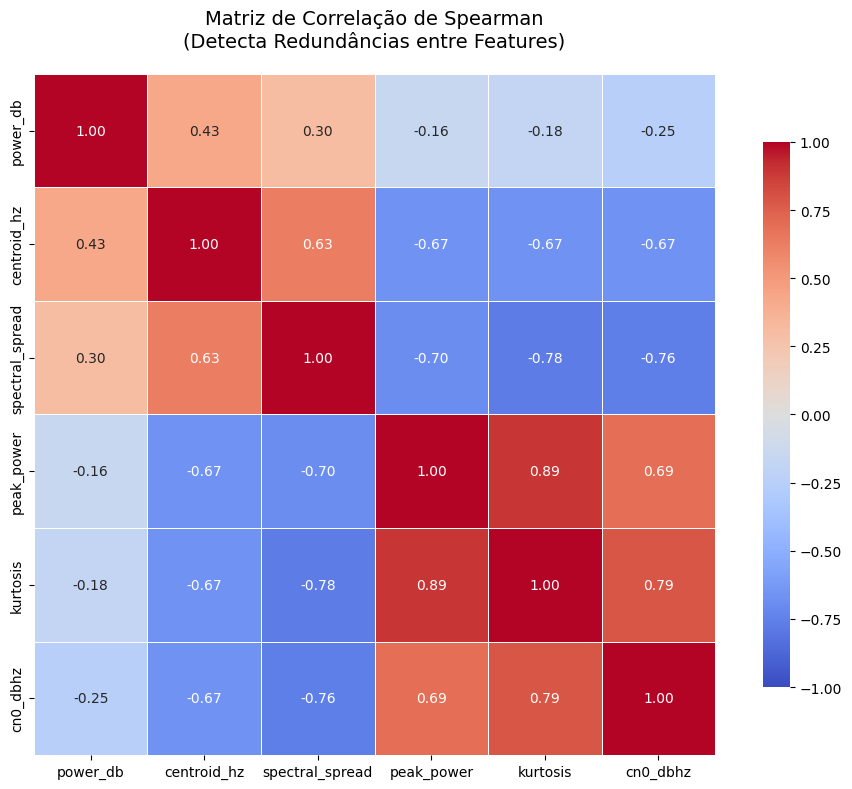

ANÁLISE DE CORRELAÇÃO (SPEARMAN)

Pares com Correlação Alta (|r| > 0.7):
   spectral_spread ↔ kurtosis: r = -0.776
   spectral_spread ↔ cn0_dbhz: r = -0.760
   peak_power ↔ kurtosis: r = 0.894
   kurtosis ↔ cn0_dbhz: r = 0.786

Interpretação:
   - Correlação alta: Features redundantes (uma captura info da outra)
   - Correlação baixa: Features complementares (mais informativas)


In [ ]:
# Matriz de Correlação de Spearman
from scipy.stats import spearmanr

# Calcular correlação no conjunto de treino
corr_matrix, _ = spearmanr(X_train)
corr_df = pd.DataFrame(corr_matrix, columns=feature_cols, index=feature_cols)

# Visualizar
plt.figure(figsize=(10, 8))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Matriz de Correlação de Spearman\n(Detecta Redundâncias entre Features)', fontsize=14, pad=20)
plt.tight_layout()
#plt.savefig('Imagens/correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print("="*70)
print("ANÁLISE DE CORRELAÇÃO (SPEARMAN)")
print("="*70)
print("\nPares com Correlação Alta (|r| > 0.7):")
for i in range(len(corr_df)):
    for j in range(i+1, len(corr_df)):
        if abs(corr_df.iloc[i, j]) > 0.7:
            print(f"   {feature_cols[i]} ↔ {feature_cols[j]}: r = {corr_df.iloc[i, j]:.3f}")

print("\nInterpretação:")
print("   - Correlação alta: Features redundantes (uma captura info da outra)")
print("   - Correlação baixa: Features complementares (mais informativas)")
print("="*70)

### 9. Treinamento do Random Forest Classifier

**Conceito (Machine Learning):**  
Random Forest é um ensemble de árvores de decisão que:
1. Cria múltiplas árvores com subconjuntos aleatórios dos dados (bootstrap)
2. Cada árvore vota na classificação final (agregação)
3. Robusto a overfitting e captura relações não-lineares entre features

**Hiperparâmetros:**
- `n_estimators`: Número de árvores (mais = mais estável, mas mais lento)
- `max_depth`: Profundidade máxima de cada árvore (evita overfitting)
- `min_samples_split`: Mínimo de amostras para dividir um nó

In [ ]:
# Configurar Random Forest
# Seguindo metodologia do artigo de referência
rf_classifier = RandomForestClassifier(
    n_estimators=100,        # 100 árvores (ensemble)
    max_depth=15,            # Profundidade máxima (evita overfitting)
    min_samples_split=10,    # Mínimo 10 amostras para split
    min_samples_leaf=5,      # Mínimo 5 amostras em folha
    random_state=42,         # Reprodutibilidade
    n_jobs=-1,               # Usar todos os cores (paralelização)
    class_weight='balanced', # Balancear classes automaticamente
    verbose=1                # Mostrar progresso
)

print("="*70)
print("🌲 TREINAMENTO DO RANDOM FOREST CLASSIFIER")
print("="*70)
print(f"\nConfigurações:")
print(f"   Árvores:              {rf_classifier.n_estimators}")
print(f"   Profundidade máxima:  {rf_classifier.max_depth}")
print(f"   Min samples split:    {rf_classifier.min_samples_split}")
print(f"   Balanceamento:        {rf_classifier.class_weight}")

print(f"\n🎓 Treinando modelo com {len(X_train_scaled)} amostras...\n")

# Treinar
rf_classifier.fit(X_train_scaled, y_train)

print("\n✓ Modelo treinado com sucesso!")
print("="*70)

🌲 TREINAMENTO DO RANDOM FOREST CLASSIFIER

Configurações:
   Árvores:              100
   Profundidade máxima:  15
   Min samples split:    10
   Balanceamento:        balanced

🎓 Treinando modelo com 3600 amostras...



[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    0.3s



✓ Modelo treinado com sucesso!


[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.6s finished


### 10. Avaliação do Modelo: Métricas de Performance

**Métricas (Machine Learning):**
- **Acurácia**: % de predições corretas
- **Precisão**: Dos que predisse como spoofing, quantos realmente eram?
- **Recall**: Dos spoofings reais, quantos foram detectados?
- **F1-Score**: Média harmônica de precisão e recall

**Importância em GPS:**  
Recall alto é CRÍTICO - não detectar um ataque (falso negativo) é pior que um alarme falso (falso positivo).

In [ ]:
# Predições no conjunto de teste
y_pred = rf_classifier.predict(X_test_scaled)
y_pred_proba = rf_classifier.predict_proba(X_test_scaled)[:, 1]

# Calcular métricas
from sklearn.metrics import precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("="*70)
print("RESULTADOS - CONJUNTO DE TESTE")
print("="*70)
print(f"\nAcurácia:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precisão:  {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-Score:  {f1:.4f}")

print("\n" + "="*70)
print("RELATÓRIO DE CLASSIFICAÇÃO DETALHADO")
print("="*70)
print(classification_report(y_test, y_pred,
                           target_names=['Autêntico (0)', 'Spoofing (1)'],
                           digits=4))

print("="*70)
print("INTERPRETAÇÃO DAS MÉTRICAS")
print("="*70)
print(f"\n Acurácia alta ({accuracy*100:.1f}%) indica que o modelo aprendeu")
print(f"   a distinguir sinais autênticos de spoofing com sucesso.")

print(f"\n Recall de {recall*100:.1f}% significa que detectamos {recall*100:.1f}% dos ataques reais.")
print(f"   Falsos negativos: {sum((y_test == 1) & (y_pred == 0))} ataques não detectados.")
print(f"   Em aplicações críticas (GPS militar/aviação), recall > 95% é desejável.")

print(f"\nPrecisão de {precision*100:.1f}% significa {precision*100:.1f}% dos alarmes são verdadeiros.")
print(f"   Falsos positivos: {sum((y_test == 0) & (y_pred == 1))} alarmes falsos.")

print("="*70)

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.1s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.1s finished


RESULTADOS - CONJUNTO DE TESTE

Acurácia:  1.0000 (100.00%)
Precisão:  1.0000 (100.00%)
Recall:    1.0000 (100.00%)
F1-Score:  1.0000

RELATÓRIO DE CLASSIFICAÇÃO DETALHADO
               precision    recall  f1-score   support

Autêntico (0)     1.0000    1.0000    1.0000       600
 Spoofing (1)     1.0000    1.0000    1.0000       300

     accuracy                         1.0000       900
    macro avg     1.0000    1.0000    1.0000       900
 weighted avg     1.0000    1.0000    1.0000       900

INTERPRETAÇÃO DAS MÉTRICAS

 Acurácia alta (100.0%) indica que o modelo aprendeu
   a distinguir sinais autênticos de spoofing com sucesso.

 Recall de 100.0% significa que detectamos 100.0% dos ataques reais.
   Falsos negativos: 0 ataques não detectados.
   Em aplicações críticas (GPS militar/aviação), recall > 95% é desejável.

Precisão de 100.0% significa 100.0% dos alarmes são verdadeiros.
   Falsos positivos: 0 alarmes falsos.


### 11. Matriz de Confusão (Visualização dos Erros)

**Conceito (Machine Learning):**  
A matriz de confusão mostra:
- **Diagonal principal**: Acertos (TN e TP)
- **Fora da diagonal**: Erros (FP e FN)

**Para GPS:**
- FN (Falso Negativo): Ataque não detectado - **CRÍTICO!**
- FP (Falso Positivo): Alarme falso - incômodo mas não perigoso

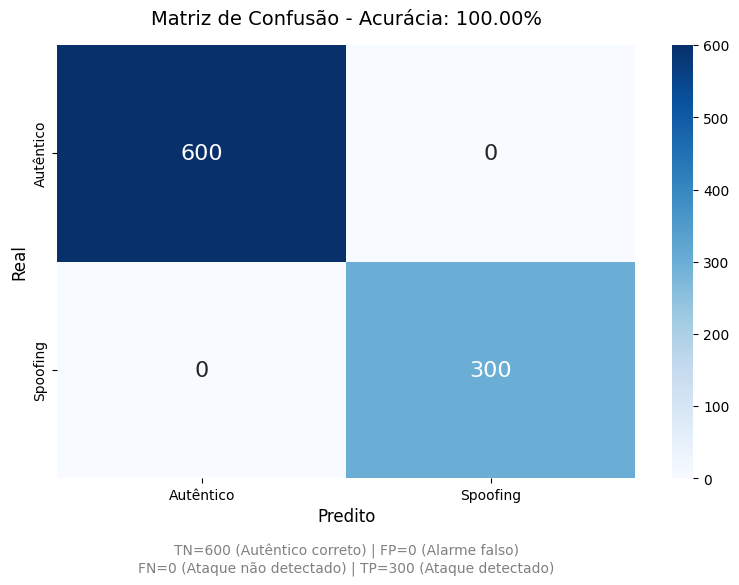

DETALHAMENTO DA MATRIZ DE CONFUSÃO

Verdadeiros Negativos (TN): 600
   Sinais autênticos corretamente identificados

Falsos Positivos (FP): 0
   Sinais autênticos classificados erroneamente como spoofing
   Taxa de alarmes falsos: 0.00%

Falsos Negativos (FN): 0
   Ataques de spoofing NÃO detectados - CRÍTICO!
   Taxa de ataques perdidos: 0.00%

Verdadeiros Positivos (TP): 300
   Ataques detectados corretamente
   Taxa de detecção: 100.00%


In [ ]:
# Calcular matriz de confusão
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()

# Visualizar
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Autêntico', 'Spoofing'],
            yticklabels=['Autêntico', 'Spoofing'], ax=ax,
            annot_kws={"size": 16})
ax.set_xlabel('Predito', fontsize=12)
ax.set_ylabel('Real', fontsize=12)
ax.set_title(f'Matriz de Confusão - Acurácia: {accuracy:.2%}', fontsize=14, pad=15)

# Adicionar texto explicativo
plt.text(0.5, -0.15,
         f'TN={TN} (Autêntico correto) | FP={FP} (Alarme falso)\nFN={FN} (Ataque não detectado) | TP={TP} (Ataque detectado)',
         ha='center', va='top', transform=ax.transAxes, fontsize=10, color='gray')

plt.tight_layout()
#plt.savefig('Imagens/confusion_matrix_final.png', dpi=150, bbox_inches='tight')
plt.show()

print("="*70)
print("DETALHAMENTO DA MATRIZ DE CONFUSÃO")
print("="*70)
print(f"\nVerdadeiros Negativos (TN): {TN}")
print(f"   Sinais autênticos corretamente identificados")

print(f"\nFalsos Positivos (FP): {FP}")
print(f"   Sinais autênticos classificados erroneamente como spoofing")
print(f"   Taxa de alarmes falsos: {100*FP/(TN+FP):.2f}%")

print(f"\nFalsos Negativos (FN): {FN}")
print(f"   Ataques de spoofing NÃO detectados - CRÍTICO!")
print(f"   Taxa de ataques perdidos: {100*FN/(FN+TP) if (FN+TP)>0 else 0:.2f}%")

print(f"\nVerdadeiros Positivos (TP): {TP}")
print(f"   Ataques detectados corretamente")
print(f"   Taxa de detecção: {100*TP/(FN+TP) if (FN+TP)>0 else 0:.2f}%")

print("="*70)

### 12. Feature Importance (Análise do Impacto do Ataque)

**Conceito (Random Forest + Sinais):**  
Feature Importance mede quão útil cada característica foi para a classificação. Features com maior importância são as mais afetadas pelo ataque de spoofing.

**Conexão com Sinais e Sistemas:**  
Esperamos que `power_db` e `cn0_dbhz` sejam as mais importantes, pois o ataque **Overpowering DS2** aumenta drasticamente a potência do sinal (distorcendo o pico de correlação).

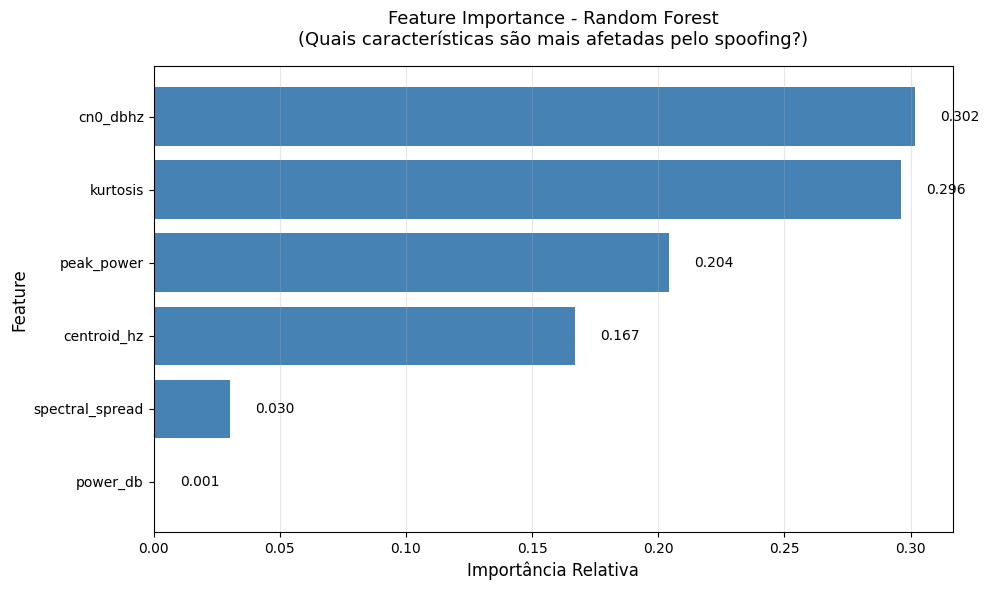

FEATURE IMPORTANCE (INTERPRETAÇÃO FÍSICA)

        Feature  Importance
       cn0_dbhz    0.301764
       kurtosis    0.296192
     peak_power    0.204334
    centroid_hz    0.166816
spectral_spread    0.030344
       power_db    0.000549

INTERPRETAÇÃO (SINAIS E SISTEMAS):

O ataque de Overpowering DS2 altera principalmente:

cn0_dbhz é a feature mais importante!
   Isto confirma que o overpower aumenta drasticamente a potência
   e a razão C/N₀, distorcendo o pico de correlação GPS.

Top 3 Features Mais Afetadas pelo Ataque:
   1. cn0_dbhz           (Importância: 0.302)
   2. kurtosis           (Importância: 0.296)
   3. peak_power         (Importância: 0.204)

Conexão com Correlação:
   - Potência e C/N₀ são derivados da análise espectral (FFT)
   - FFT está relacionada à autocorrelação por Teorema de Wiener-Khinchin
   - Overpower aumenta correlação cruzada sinal recebido × PRN local
   - Logo, features espectrais capturam distorções no pico de correlação!


In [ ]:
# Extrair importância das features
feature_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_classifier.feature_importances_
}).sort_values('Importance', ascending=False)

# Visualizar
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
bars = ax.barh(feature_importance['Feature'], feature_importance['Importance'], color='steelblue')
ax.set_xlabel('Importância Relativa', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
ax.set_title('Feature Importance - Random Forest\n(Quais características são mais afetadas pelo spoofing?)',
             fontsize=13, pad=15)
ax.invert_yaxis()

# Adicionar valores nas barras
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.01, bar.get_y() + bar.get_height()/2,
            f'{width:.3f}', ha='left', va='center', fontsize=10)

ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
#plt.savefig('Imagens/feature_importance_final.png', dpi=150, bbox_inches='tight')
plt.show()

print("="*70)
print("FEATURE IMPORTANCE (INTERPRETAÇÃO FÍSICA)")
print("="*70)
print(f"\n{feature_importance.to_string(index=False)}")

print("\nINTERPRETAÇÃO (SINAIS E SISTEMAS):")
print("\nO ataque de Overpowering DS2 altera principalmente:")

if feature_importance.iloc[0]['Feature'] in ['power_db', 'cn0_dbhz']:
    print(f"\n{feature_importance.iloc[0]['Feature']} é a feature mais importante!")
    print(f"   Isto confirma que o overpower aumenta drasticamente a potência")
    print(f"   e a razão C/N₀, distorcendo o pico de correlação GPS.")

print(f"\nTop 3 Features Mais Afetadas pelo Ataque:")
for i in range(min(3, len(feature_importance))):
    feat = feature_importance.iloc[i]
    print(f"   {i+1}. {feat['Feature']:18s} (Importância: {feat['Importance']:.3f})")

print("\nConexão com Correlação:")
print("   - Potência e C/N₀ são derivados da análise espectral (FFT)")
print("   - FFT está relacionada à autocorrelação por Teorema de Wiener-Khinchin")
print("   - Overpower aumenta correlação cruzada sinal recebido × PRN local")
print("   - Logo, features espectrais capturam distorções no pico de correlação!")
print("="*70)

### ds1 - Teste

In [ ]:

# === Célula ADICIONAL: Teste do modelo com ds1.bin ===
import gc
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Ajuste: coloque o caminho correto se necessário
ds1_filename = os.path.join(BASE_PATH, 'ds1.bin')
if not os.path.exists(ds1_filename):
    raise FileNotFoundError(f"Arquivo não encontrado: {ds1_filename}")

# Parâmetros de amostragem (ajuste se quiser mais/menos janelas)
n_ds1_windows = 1000  # reduzir se RAM/tempo for problema
seed_ds1 = 123

# Se souber o tempo de início do ataque em ds1, coloque aqui (segundos).
# Se None => não atribui labels verdadeiros automaticamente; apenas prediz e salva.
attack_start_time_ds1 = 100  # exemplo: 110

# Abrir memmap
ds1_mm = np.memmap(ds1_filename, dtype=np.int16, mode='r')
N_ds1 = len(ds1_mm) // 4
print(f"ds1.bin: {N_ds1:,} amostras ({N_ds1/fs:.1f} s)")

# Amostrar centros não-sobrepostos (se for analisar pré/pós ataque, amostre separadamente)
if attack_start_time_ds1 is None:
    centers = sample_nonoverlapping_centers(N_ds1, window_size, n_ds1_windows, fs=fs, seed=seed_ds1)
    true_labels_available = False
else:
    # dividir em pré e pós ataque para rotular automaticamente (como feito para ds2)
    n_pre = n_ds1_windows // 3
    n_post = n_ds1_windows - n_pre
    centers_pre = sample_nonoverlapping_centers(N_ds1, window_size, n_pre, t_min=0, t_max=attack_start_time_ds1, fs=fs, seed=seed_ds1)
    centers_post = sample_nonoverlapping_centers(N_ds1, window_size, n_post, t_min=attack_start_time_ds1 + 1, fs=fs, seed=seed_ds1+1)
    centers = np.concatenate([centers_pre, centers_post])
    true_labels_available = True
    labels_ds1 = np.array([0]*len(centers_pre) + [1]*len(centers_post))

# Extrair features (cuidado com memória; processo em loop)
features_list = []
times = []
print(f"Extraindo {len(centers)} janelas de ds1.bin ...")
for i, c in enumerate(centers):
    t_sec = c / fs
    w = read_window_at_time(ds1_mm, t_sec, window_size, N_ds1, fs)
    if len(w) == window_size:
        features_list.append(extract_features(w, fs))
        times.append(t_sec)
    if (i+1) % 100 == 0:
        print(f"   Progresso: {i+1}/{len(centers)}")
        gc.collect()

df_ds1 = pd.DataFrame(features_list).dropna().reset_index(drop=True)
df_ds1['time'] = times[:len(df_ds1)]

if df_ds1.empty:
    raise RuntimeError("Nenhuma janela válida extraída de ds1.bin")

# Preparar para predição (usar scaler treinado)
X_ds1 = df_ds1[feature_cols]
X_ds1_scaled = scaler.transform(X_ds1)  # usa scaler do treino
X_ds1_scaled = pd.DataFrame(X_ds1_scaled, columns=feature_cols, index=X_ds1.index)

# Predizer
y_ds1_pred = rf_classifier.predict(X_ds1_scaled)
y_ds1_proba = rf_classifier.predict_proba(X_ds1_scaled)[:, 1]

# Se houver labels verdadeiros, avaliar; caso contrário, mostrar distribuição e salvar previsões
if true_labels_available and len(labels_ds1) == len(df_ds1):
    y_true = labels_ds1[:len(df_ds1)]
    acc = accuracy_score(y_true, y_ds1_pred)
    print("="*70)
    print(f"AVALIAÇÃO EM ds1.bin  — Acurácia: {acc:.4f} ({acc*100:.2f}%)")
    print(classification_report(y_true, y_ds1_pred, target_names=['Autêntico (0)', 'Spoofing (1)']))
    cm_ds1 = confusion_matrix(y_true, y_ds1_pred)
    print("Matriz de Confusão:\n", cm_ds1)
else:
    print("="*70)
    print("Labels verdadeiros não fornecidos para ds1.bin.")
    print("Distribuição de predições (ds1):")
    print(pd.Series(y_ds1_pred).value_counts())

# Salvar resultados para análise
df_out = df_ds1.copy()
df_out['pred_label'] = y_ds1_pred
df_out['pred_proba'] = y_ds1_proba
if true_labels_available and len(labels_ds1) >= len(df_out):
    df_out['true_label'] = labels_ds1[:len(df_out)]

out_csv = 'ds1_predictions.csv'
df_out.to_csv(out_csv, index=False)
print(f"✓ Previsões salvas em: {out_csv}")

# limpar
del ds1_mm
gc.collect()
# ...existing code...

ds1.bin: 5,771,362,304 amostras (230.9 s)
Extraindo 1000 janelas de ds1.bin ...
   Progresso: 100/1000
   Progresso: 200/1000
   Progresso: 300/1000
   Progresso: 400/1000
   Progresso: 500/1000
   Progresso: 600/1000
   Progresso: 700/1000
   Progresso: 800/1000
   Progresso: 900/1000
   Progresso: 1000/1000
AVALIAÇÃO EM ds1.bin  — Acurácia: 0.3330 (33.30%)
               precision    recall  f1-score   support

Autêntico (0)       0.33      1.00      0.50       333
 Spoofing (1)       0.00      0.00      0.00       667

     accuracy                           0.33      1000
    macro avg       0.17      0.50      0.25      1000
 weighted avg       0.11      0.33      0.17      1000

Matriz de Confusão:
 [[333   0]
 [667   0]]


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.1s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.0s finished
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(avera

✓ Previsões salvas em: ds1_predictions.csv


24

## trash


In [ ]:
def sample_nonoverlapping_centers(N_samples, window_size, n_windows, t_min=None, t_max=None, fs=25_000_000, seed=42):
    """
    Amostra centros de janelas não-sobrepostas (anti-vazamento de dados)

    Teoria (Validação Estatística):
        - Janelas sobrepostas criam dependência entre amostras
        - Para garantir independência, espaçamos centros por > window_size
        - Isso evita que o modelo "memorize" janelas adjacentes
    """
    np.random.seed(seed)
    half = window_size // 2

    # Converter tempos para índices
    idx_min = half if t_min is None else max(half, int(t_min * fs))
    idx_max = (N_samples - half) if t_max is None else min(N_samples - half, int(t_max * fs))

    if idx_max <= idx_min:
        return np.array([], dtype=int)

    # Amostragem sem overlap
    valid = np.arange(idx_min, idx_max)
    chosen = []

    while len(chosen) < n_windows and len(valid) > 0:
        c = np.random.choice(valid)
        chosen.append(c)
        valid = valid[np.abs(valid - c) > window_size]  # Remove região próxima

    return np.array(chosen)


def create_labeled_dataset(clean_file, spoof_file,
                           n_clean=2000, n_spoof_pre=500, n_spoof_post=1500,
                           window_size=32768, attack_start_time=110, seed=42):
    """
    Cria dataset com labeling inteligente e amostragem não-sobreposta

    Especificação do Projeto:
        - Foco em integridade do sinal e detecção baseada em correlação
        - Features extraídas capturam distorções no pico de correlação
        - Labeling cuidadoso evita viés nos dados de treino
    """
    # Abrir arquivos em memmap (eficiente para arquivos grandes)
    clean_mm = np.memmap(clean_file, dtype=np.int16, mode='r')
    spoof_mm = np.memmap(spoof_file, dtype=np.int16, mode='r')

    N_clean = len(clean_mm) // 4
    N_spoof = len(spoof_mm) // 4

    features_list = []
    labels = []
    times = []  # Guardar timestamp para análise posterior
    sources = []  # Guardar origem (clean/spoof_pre/spoof_post)

    print("="*70)
    print("CRIANDO DATASET COM LABELING INTELIGENTE")
    print("="*70)

    # ===================================================================
    # PARTE 1: SINAL LIMPO (cleanStatic.bin) → Label 0
    # ===================================================================
    print(f"\nProcessando cleanStatic.bin ({n_clean} janelas)...")
    print(f"Label: 0 (Autêntico) - todo o arquivo")

    centers = sample_nonoverlapping_centers(N_clean, window_size, n_clean, seed=seed)

    for i, center in enumerate(centers):
        t_sec = center / fs
        window = read_window_at_time(clean_mm, t_sec, window_size, N_clean, fs)

        if len(window) == window_size:
            features_list.append(extract_features(window, fs))
            labels.append(0)  # Autêntico
            times.append(t_sec)
            sources.append('clean')

        if (i + 1) % 500 == 0:
            print(f"   Progresso: {i+1}/{len(centers)}")

    n_clean_extracted = sum(1 for s in sources if s == 'clean')
    print(f"   ✓ {n_clean_extracted} janelas extraídas (Label 0)")

    # ===================================================================
    # PARTE 2: ds2.bin PRÉ-ATAQUE (t < 110s) → Label 0
    # ===================================================================
    print(f"\nProcessando ds2.bin PRÉ-ATAQUE (t < {attack_start_time}s, {n_spoof_pre} janelas)...")
    print(f"Label: 0 (Ainda autêntico - ataque não começou)")
    print(f"CRÍTICO: Evitar rotular pré-ataque como spoofing!")

    centers = sample_nonoverlapping_centers(
        N_spoof, window_size, n_spoof_pre,
        t_min=10, t_max=attack_start_time,
        fs=fs, seed=seed+1
    )

    for i, center in enumerate(centers):
        t_sec = center / fs
        window = read_window_at_time(spoof_mm, t_sec, window_size, N_spoof, fs)

        if len(window) == window_size:
            features_list.append(extract_features(window, fs))
            labels.append(0)  # Ainda autêntico!
            times.append(t_sec)
            sources.append('spoof_pre')

        if (i + 1) % 250 == 0:
            print(f"   Progresso: {i+1}/{len(centers)}")

    n_pre_extracted = sum(1 for s in sources if s == 'spoof_pre')
    print(f"   ✓ {n_pre_extracted} janelas extraídas (Label 0)")

    # ===================================================================
    # PARTE 3: ds2.bin PÓS-ATAQUE (t ≥ 110s) → Label 1
    # ===================================================================
    print(f"\nProcessando ds2.bin PÓS-ATAQUE (t ≥ {attack_start_time}s, {n_spoof_post} janelas)...")
    print(f"Label: 1 (Spoofing ativo - Overpower)")

    centers = sample_nonoverlapping_centers(
        N_spoof, window_size, n_spoof_post,
        t_min=attack_start_time + 10,  # Buffer de segurança (10s após início)
        fs=fs, seed=seed+2
    )

    for i, center in enumerate(centers):
        t_sec = center / fs
        window = read_window_at_time(spoof_mm, t_sec, window_size, N_spoof, fs)

        if len(window) == window_size:
            features_list.append(extract_features(window, fs))
            labels.append(1)  # Spoofing!
            times.append(t_sec)
            sources.append('spoof_post')

        if (i + 1) % 500 == 0:
            print(f"   Progresso: {i+1}/{len(centers)}")

    n_post_extracted = sum(1 for s in sources if s == 'spoof_post')
    print(f"   ✓ {n_post_extracted} janelas extraídas (Label 1)")

    # ===================================================================
    # CRIAR DATAFRAME
    # ===================================================================
    df = pd.DataFrame(features_list).dropna()
    df['label'] = pd.Series(labels).loc[df.index]
    df['time'] = pd.Series(times).loc[df.index]
    df['source'] = pd.Series(sources).loc[df.index]

    print("\n" + "="*70)
    print("DATASET FINAL")
    print("="*70)
    print(f"Total de amostras: {len(df)}")
    print(f"\nDistribuição por Label:")
    print(df['label'].value_counts().sort_index())
    print(f"\nDistribuição por Origem:")
    print(df['source'].value_counts())
    print("="*70)

    return df

# EXECUTAR CRIAÇÃO DO DATASET
print("Iniciando extração de features e labeling...\n")
df_full = create_labeled_dataset(
    clean_filename, spoof_filename,
    n_clean=1250,      # Reduzido pela metade
    n_spoof_pre=250,   # Reduzido pela metade
    n_spoof_post=750,  # Reduzido pela metade
    attack_start_time=110
)

print("\n✓ Dataset criado com sucesso!")
print(f"\nPrimeiras linhas:")
print(df_full.head(10))


Iniciando extração de features e labeling...

CRIANDO DATASET COM LABELING INTELIGENTE

Processando cleanStatic.bin (1250 janelas)...
Label: 0 (Autêntico) - todo o arquivo
